<a href="https://colab.research.google.com/github/Sasidhar015/Data-engineering-training-2026/blob/main/Capstone%20Projects/Personal%20Expense%20Monitoring%20System/Week%202/expense_processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np

try:
    from google.colab import files
    uploaded = files.upload()
    EXP, USR = "expenses.csv", "users.csv"
except ImportError:
    EXP, USR = "data/expenses.csv", "data/users.csv"

df = pd.read_csv(EXP)
users = pd.read_csv(USR)
print(df.shape)
df.head(10)

Saving expenses.csv to expenses.csv
Saving users.csv to users.csv
(575, 7)


,expense_id,user_id,category,amount,date,description,payment_method
0,1,1,Rent,"$1,060.50","April 01, 2026",rent purchase,UPI
1,2,1,Utilities,79.66,01-Apr-2026,utilities purchase,Debit Card
2,3,1,Entertainment,22.2,2026-04-08,entertainment purchase,UPI
3,4,1,Dining,$40.55,"April 05, 2026",dining purchase,Cash
4,5,1,Utilities,$95.56,"April 22, 2026",utilities purchase,Cash
5,6,1,Utilities,$81.32,"April 19, 2026",utilities purchase,Credit Card
6,7,1,Shopping,$103.82,"April 02, 2026",shopping purchase,Debit Card
7,8,1,Groceries,52.01,"April 03, 2026",groceries purchase,Credit Card
8,9,1,Dining,19.69,2026-04-08,dining purchase,Cash
9,10,1,Groceries,$50.53,18-Apr-2026,groceries purchase,UPI


In [5]:
print(df.dtypes, "\n")
print("Missing values:\n", df.isna().sum(), "\n")
print("Duplicate rows:", df.duplicated().sum())
print("Raw categories:", sorted(df["category"].dropna().unique()))

expense_id         int64
user_id            int64
category          object
amount            object
date              object
description       object
payment_method    object
dtype: object 

Missing values:
 expense_id        0
user_id           0
category          0
amount            4
date              0
description       0
payment_method    0
dtype: int64 

Duplicate rows: 5
Raw categories: [' Dining ', ' Education ', ' Entertainment ', ' Groceries ', ' Health ', ' Shopping ', ' Utilities ', 'DINING', 'Dining', 'EDUCATION', 'ENTERTAINMENT', 'Education', 'Entertainment', 'GROCERIES', 'Groceries', 'HEALTH', 'Health', 'RENT', 'Rent', 'SHOPPING', 'Shopping', 'TRANSPORT', 'Transport', 'UTILITIES', 'Utilities', 'dining', 'education', 'entertainment', 'groceries', 'health', 'rent', 'shopping', 'transport']


In [18]:
clean = df.copy()

clean = clean.drop_duplicates()

clean["amount"] = (clean["amount"].astype(str)
                   .str.replace(r"[\$,]", "", regex=True)
                   .replace({"nan": np.nan, "None": np.nan, "": np.nan})
                   .astype(float))

clean["date"] = pd.to_datetime(clean["date"], format="mixed", errors="coerce")


clean["category"] = clean["category"].str.strip().str.title()

before = len(clean)
clean = clean.dropna(subset=["amount", "date"])
clean = clean[clean["amount"] > 0]
print(f"Dropped {before - len(clean)} unusable rows -> {len(clean)} remain")

clean["month"] = clean["date"].dt.to_period("M")
clean = clean.sort_values(["user_id", "date"]).reset_index(drop=True)
clean.head()

Dropped 4 unusable rows -> 566 remain


,expense_id,user_id,category,amount,date,description,payment_method,month
0,1,1,Rent,1060.50,2026-04-01,rent purchase,UPI,2026-04
1,2,1,Utilities,79.66,2026-04-01,utilities purchase,Debit Card,2026-04
2,7,1,Shopping,103.82,2026-04-02,shopping purchase,Debit Card,2026-04
3,8,1,Groceries,52.01,2026-04-03,groceries purchase,Credit Card,2026-04
4,4,1,Dining,40.55,2026-04-05,dining purchase,Cash,2026-04


In [17]:
monthly_user = clean.groupby(["user_id", "month"])["amount"].sum().unstack(fill_value=0)

totals = monthly_user.to_numpy()
stats = pd.DataFrame({
    "avg_monthly_spend": np.round(totals.mean(axis=1), 2),
    "median_monthly":    np.round(np.median(totals, axis=1), 2),
    "std_dev":           np.round(totals.std(axis=1), 2),
    "max_month_spend":   np.round(totals.max(axis=1), 2),
    "peak_month":        monthly_user.idxmax(axis=1).astype(str),
}, index=monthly_user.index)

print("Overall average monthly spend per user:", round(float(totals.mean()), 2))
stats

Overall average monthly spend per user: 3004.3


,avg_monthly_spend,median_monthly,std_dev,max_month_spend,peak_month
user_id,,,,,
1,2445.35,2045.10,1045.42,4764.79,2026-04
2,3265.17,3251.24,158.24,3534.11,2026-04
3,3980.39,3096.94,2027.89,8514.35,2026-04
4,2630.42,2627.66,144.38,2877.41,2026-06
5,2700.18,2667.34,160.18,2980.31,2026-06


In [15]:
monthly_expense = (clean.groupby(["month", "category"])["amount"]
                        .sum().unstack().fillna(0).round(2))
print(monthly_expense)


cat_share = (clean.groupby("category")["amount"].sum()
                  .sort_values(ascending=False).to_frame("total"))
cat_share["pct"] = (100 * cat_share["total"] / cat_share["total"].sum()).round(1)
cat_share

category  Dining  Education  Entertainment  Groceries  Health    Rent  \
month                                                                   
2026-04   607.56    1072.42         229.59     566.50  228.14  8800.8   
2026-05   363.52     581.82         613.55     432.14  554.00  8800.8   
2026-06   409.69    1609.42         325.20     460.76  739.02  8800.8   
2026-07   368.39    1206.23         521.10     385.86  552.42  8800.8   
2026-08   352.88    1263.74         705.92     443.88  557.11  8800.8   
2026-09   307.88    1053.46         151.94     711.53  265.99  8800.8   

category  Shopping  Transport  Utilities  
month                                     
2026-04    9245.10     122.68    1298.17  
2026-05     827.33     157.63    1392.63  
2026-06     624.69     254.72     849.48  
2026-07     833.51     176.41     792.96  
2026-08     357.20     376.05     399.16  
2026-09    1061.87     355.14     557.83  


,total,pct
category,,
Rent,52804.80,58.6
Shopping,12949.70,14.4
Education,6787.09,7.5
Utilities,5290.23,5.9
Groceries,3000.67,3.3
Health,2896.68,3.2
Entertainment,2547.30,2.8
Dining,2409.92,2.7
Transport,1442.63,1.6


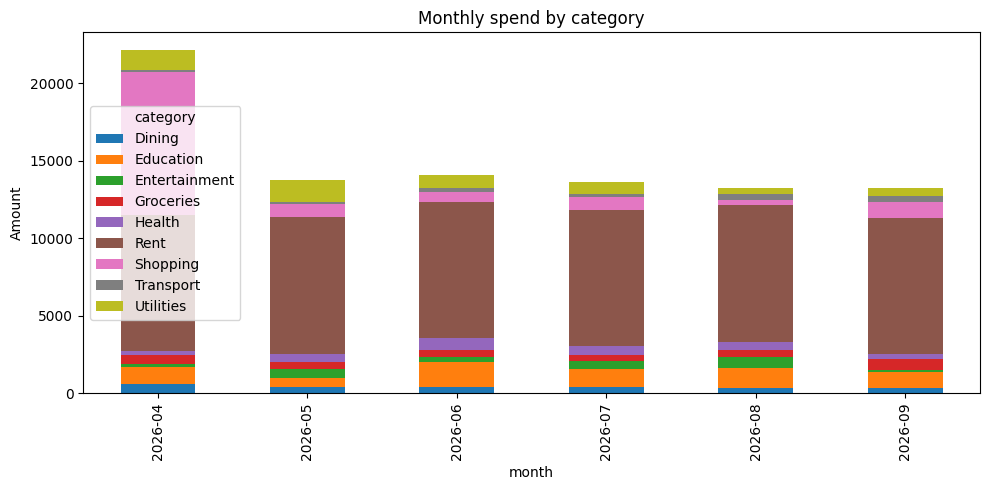

In [12]:
import matplotlib.pyplot as plt
monthly_expense.plot(kind="bar", stacked=True, figsize=(10, 5), title="Monthly spend by category")
plt.ylabel("Amount"); plt.tight_layout(); plt.show()

In [13]:
summary = (clean.groupby(["user_id", "month"])["amount"].sum()
                .rename("total_spend").reset_index()
                .merge(users[["user_id", "monthly_income", "monthly_budget"]], on="user_id"))
summary["savings"] = summary["monthly_income"] - summary["total_spend"]
summary["over_budget"] = summary["total_spend"] > summary["monthly_budget"]
summary["month"] = summary["month"].astype(str)
summary.round(2).head(12)

,user_id,month,total_spend,monthly_income,monthly_budget,savings,over_budget
0,1,2026-04,4764.79,3535,2614.0,-1229.79,True
1,1,2026-05,2134.99,3535,2614.0,1400.01,False
2,1,2026-06,1952.08,3535,2614.0,1582.92,False
3,1,2026-07,2099.19,3535,2614.0,1435.81,False
4,1,2026-08,1730.04,3535,2614.0,1804.96,False
5,1,2026-09,1991.01,3535,2614.0,1543.99,False
6,2,2026-04,3534.11,7643,4730.0,4108.89,False
7,2,2026-05,3324.37,7643,4730.0,4318.63,False
8,2,2026-06,3235.20,7643,4730.0,4407.80,False
9,2,2026-07,3256.09,7643,4730.0,4386.91,False


In [14]:
clean.assign(month=clean["month"].astype(str)).to_csv("expenses_clean.csv", index=False)
monthly_expense.to_csv("monthly_category_summary.csv")
summary.round(2).to_csv("user_monthly_summary.csv", index=False)

try:
    from google.colab import files
    for f in ["expenses_clean.csv", "monthly_category_summary.csv", "user_monthly_summary.csv"]:
        files.download(f)
except ImportError:
    pass
print("Saved: expenses_clean.csv, monthly_category_summary.csv, user_monthly_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved: expenses_clean.csv, monthly_category_summary.csv, user_monthly_summary.csv
